# Chapitre 2 — Mesure, statistiques et indétermination

On mesure $\sigma_n$ sur un état préparé, on compare la fréquence des résultats à la règle de Born, puis on vérifie la relation de Robertson $\Delta\sigma_x\Delta\sigma_y \ge |\langle\sigma_z\rangle|$.

*Carnet PHY321 — fonctionne sans connexion : numpy et matplotlib suffisent.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # graine fixe : résultats reproductibles

In [2]:
sx = np.array([[0,1],[1,0]]); sy = np.array([[0,-1j],[1j,0]]); sz = np.array([[1,0],[0,-1]])
theta, phi = 1.0, 0.5
psi = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])
n = np.array([np.sin(1.2), 0, np.cos(1.2)])           # direction de mesure
S = n[0]*sx + n[1]*sy + n[2]*sz
vals, vecs = np.linalg.eigh(S)                         # valeurs propres ±1
p = np.abs(vecs.conj().T @ psi)**2                     # règle de Born
print("valeurs propres", vals, "probabilités de Born", p)

valeurs propres [-1.  1.] probabilités de Born [0.058 0.942]


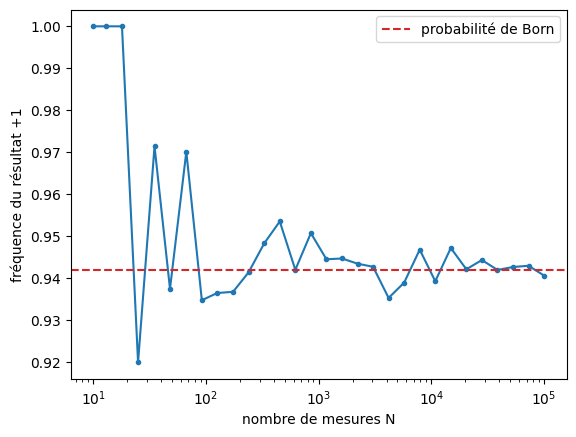

In [3]:
Ns = np.unique(np.logspace(1, 5, 30).astype(int))
freq = []
for N in Ns:
    outcomes = rng.choice(2, size=N, p=p/p.sum())
    freq.append(np.mean(outcomes == 1))
plt.semilogx(Ns, freq, 'o-', ms=3); plt.axhline(p[1], color='C3', ls='--', label="probabilité de Born")
plt.xlabel("nombre de mesures N"); plt.ylabel("fréquence du résultat +1"); plt.legend(); plt.show()

## Indétermination (Robertson)

In [4]:
def mean(A): return np.real(psi.conj() @ A @ psi)
def dev(A): return np.sqrt(mean(A @ A) - mean(A)**2)
lhs = dev(sx) * dev(sy); rhs = abs(mean(sz))
print("Δσx·Δσy =", lhs, " >= |<σz>| =", rhs, "→ vérifié", lhs >= rhs - 1e-12)
# égalité pour un état propre de σz ? (ΔσxΔσy = 1 = |<σz>|)
psi = np.array([1, 0], dtype=complex); print(dev(sx)*dev(sy), abs(mean(sz)))

Δσx·Δσy = 0.6169910161759725  >= |<σz>| = 0.5403023058681398 → vérifié True
1.0 1.0
